## Wrapper Methods

In this project, you'll analyze data from a survey conducted by Fabio Mendoza Palechor and Alexis de la Hoz Manotas that asked people about their eating habits and weight. The data was obtained from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/Estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition+). Categorical variables were changed to numerical ones in order to facilitate analysis.

First, you'll fit a logistic regression model to try to predict whether survey respondents are obese based on their answers to questions in the survey. After that, you'll use three different wrapper methods to choose a smaller feature subset.

You'll use sequential forward selection, sequential backward floating selection, and recursive feature elimination. After implementing each wrapper method, you'll evaluate the model accuracy on the resulting smaller feature subsets and compare that with the model accuracy using all available features.

In [283]:
# Import libraries
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE

## Evaluating a Logistic Regression Model

The data set `obesity` contains 18 predictor variables. Here's a brief description of them.

* `Gender` is `1` if a respondent is male and `0` if a respondent is female.
* `Age` is a respondent's age in years.
* `family_history_with_overweight` is `1` if a respondent has family member who is or was overweight, `0` if not.
* `FAVC` is `1` if a respondent eats high caloric food frequently, `0` if not.
* `FCVC` is `1` if a respondent usually eats vegetables in their meals, `0` if not.
* `NCP` represents how many main meals a respondent has daily (`0` for 1-2 meals, `1` for 3 meals, and `2` for more than 3 meals).
* `CAEC` represents how much food a respondent eats between meals on a scale of `0` to `3`.
* `SMOKE` is `1` if a respondent smokes, `0` if not.
* `CH2O` represents how much water a respondent drinks on a scale of `0` to `2`.
* `SCC` is `1` if a respondent monitors their caloric intake, `0` if not.
* `FAF` represents how much physical activity a respondent does on a scale of `0` to `3`.
* `TUE` represents how much time a respondent spends looking at devices with screens on a scale of `0` to `2`.
* `CALC` represents how often a respondent drinks alcohol on a scale of `0` to `3`.
* `Automobile`, `Bike`, `Motorbike`, `Public_Transportation`, and `Walking` indicate a respondent's primary mode of transportation. Their primary mode of transportation is indicated by a `1` and the other columns will contain a `0`.

The outcome variable, `NObeyesdad`, is a `1` if a patient is obese and a `0` if not.

Use the `.head()` method and inspect the data.

In [284]:
# https://archive.ics.uci.edu/ml/datasets/Estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition+
import pandas as pd
# Load the data
obesity = pd.read_csv("obesity.csv")
# Inspect the data
# print(obesity.head())
print("\n")
print(obesity.describe())
print("\n")
print(obesity.columns)
print(len(obesity.columns))
print("\n")
X = obesity.drop("NObeyesdad", axis=1)  # Toutes les collonnes sauf la variable cible
'''
ou
X = obesity.iloc[:, :-1] selectionne toute les collonnes sauf la derniere colonne
'''
y = obesity['NObeyesdad'] # La variable cible
'''
ou
y = obesity.iloc[:, -1] selectionne la derniere colonne uniquement
'''
print("\n")

# verification des tailles

print("X.shape", X.shape) #
print("y.shape", y.shape)  #
print("Nombre de lignes pour X et y equivalent")
print("\n")

"""
❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌COMMENT OBTENIR X et Y ????

Avant de faire le .fit(), on a besoin de X et y mais souvent on peut perdre du vu ou ils se trouvent.

🧠 1. Ce que tu observes

Tu as un dataset déjà transformé (toutes les colonnes sont numériques ✅).

Tu veux entraîner un modèle ML (.fit(X, y)), donc tu dois avoir :

X → les features (colonnes explicatives),

y → la variable cible (NObeyesdad, ici le label 0 ou 1).

Mais tu ne sais pas si :

NObeyesdad est  présent dans ton dataset.csv.

🔍 3. Vérifie d’abord

Fais :

print(obesity.columns)

ou :

list(obesity.columns)

➡️ Cela te dira quelles colonnes sont présentes.


Si tu as la colonne NObeyesdad, ✅ Donc, bonne nouvelle :
Cela veut dire que :

ton X (features) = toutes les colonnes sauf NObeyesdad

ton y (target) = la colonne NObeyesdad

💡 Voici comment tu peux le définir proprement :

# X = toutes les colonnes sauf la variable cible
X = obesity.drop("NObeyesdad", axis=1)

# y = la variable cible (0 = non obèse, 1 = obèse)
y = obesity["NObeyesdad"]

🧠 Vérifie ensuite :

print(X.shape)  # combien de lignes et colonnes pour les features
print(y.shape)  # combien de lignes pour la cible
print(y.value_counts())  # combien de 0 et de 1

Cela te permettra de confirmer :

que les dimensions sont cohérentes (X et y ont le même nombre de lignes),

et que ta variable cible contient bien des 0 et 1 (binaire).


"""




            Gender          Age  family_history_with_overweight         FAVC  \
count  2111.000000  2111.000000                     2111.000000  2111.000000   
mean      0.505921    24.312600                        0.817622     0.883941   
std       0.500083     6.345968                        0.386247     0.320371   
min       0.000000    14.000000                        0.000000     0.000000   
25%       0.000000    19.947192                        1.000000     1.000000   
50%       1.000000    22.777890                        1.000000     1.000000   
75%       1.000000    26.000000                        1.000000     1.000000   
max       1.000000    61.000000                        1.000000     1.000000   

              FCVC          NCP         CAEC        SMOKE         CH2O  \
count  2111.000000  2111.000000  2111.000000  2111.000000  2111.000000   
mean      2.419043     2.685628     1.140692     0.020843     2.008011   
std       0.533927     0.778039     0.468543     0.1428

'\n❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌COMMENT OBTENIR X et Y ????\n\nAvant de faire le .fit(), on a besoin de X et y mais souvent on peut perdre du vu ou ils se trouvent.\n\n🧠 1. Ce que tu observes\n\nTu as un dataset déjà transformé (toutes les colonnes sont numériques ✅).\n\nTu veux entraîner un modèle ML (.fit(X, y)), donc tu dois avoir :\n\nX → les features (colonnes explicatives),\n\ny → la variable cible (NObeyesdad, ici le label 0 ou 1).\n\nMais tu ne sais pas si :\n\nNObeyesdad est  présent dans ton dataset.csv.\n\n🔍 3. Vérifie d’abord\n\nFais :\n\nprint(obesity.columns)\n\nou :\n\nlist(obesity.columns)\n\n➡️ Cela te dira quelles colonnes sont présentes.\n\n\nSi tu as la colonne NObeyesdad, ✅ Donc, bonne nouvelle :\nCela veut dire que :\n\nton X (features) = toutes les colonnes sauf NObeyesdad\n\nton y (target) = la colonne NObeyesdad\n\n💡 Voici comment tu peux le définir proprement :\n\n# X = toutes les colonnes sauf la variable cible\nX = obesity.drop("NObeyesdad", axis=1)\n\n# y = la var

### Split the data into `X` and `y`

In order to use a logistic regression model, you'll need to split the data into two parts: the predictor variables and an outcome variable. Do this by splitting the data into a DataFrame of predictor variables called `X` and a Series of outcome variables `y`.

In [285]:
# Do this by splitting the data into a DataFrame of predictor variables called X and a Series of outcome variables y.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,random_state=42
)
print(X_train.shape,"\n", y_train.shape, "\n", X_test.shape,  "\n",y_test.shape)


(1688, 18) 
 (1688,) 
 (423, 18) 
 (423,)


### Logistic regression model

Create a logistic regression model called `lr`. Include the parameter `max_iter=1000` to make sure that the model will converge when you try to fit it.

In [286]:
lr = LogisticRegression(max_iter=1000)


### Fit the model

Use the `.fit()` method on `lr` to fit the model to `X` and `y`.

In [287]:
lr = LogisticRegression(max_iter=1000) # max_iter=1000 sert à s’assurer que l’optimisation converge, surtout si tu as beaucoup de features.
lr.fit(X_train, y_train) # Le modèle apprend les relations entre tes features et la variable cible.
lr.score(X_train, y_train)
lr.score(X_test, y_test)




0.7848699763593381

### Model accuracy

A model's _accuracy_ is the proportion of classes that the model correctly predicts. is Compute and print the accuracy of `lr` by using the `.score()` method. What percentage of respondents did the model correctly predict as being either obese or not obese? You may want to write this number down somewhere so that you can refer to it during future tasks.

0.758882046423496


0.7523696682464455


0.7848699763593381
Baseline Train Accuracy: 0.7523696682464455
Baseline Test Accuracy: 0.7848699763593381


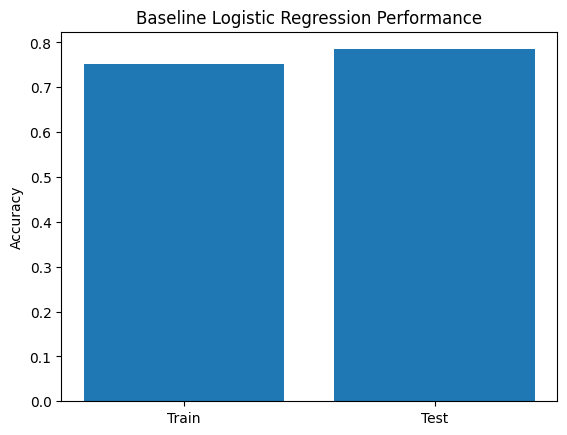

In [288]:
print(lr.score(X, y)) #❌❌❌❌ Score trompeur — modèle testé sur ce qu’il connaît déjà. Pas fiable pour juger la performance réelle. # pas recommander car on ne saura pas sil ya overfitting ou underfitting (il y a quelques conséquences pour la feature selection)
print('\n')
print(lr.score(X_train, y_train)) # Score d’entraînement → montre comment le modèle apprend sur les données qu’il a vues. Très souvent, ce score est plus élevé que sur le test, car le modèle “connaît déjà ces données”.
print('\n')
print(lr.score(X_test, y_test)) # Score de test → vraie performance sur des données nouvelles.  C’est la vraie performance, ce qui te permet de détecter overfitting ou underfitting
# donc mon model predict correctement environ 78.5% des cas ou ➡️ signifie que modèle prédit correctement environ 78.5 % des cas.


# Avant même de faire la feature selection (Sequential Forward Selection, SFS),
# il faut toujours avoir une base de comparaison — ce qu’on appelle le baseline model.
#
# Ce baseline est simplement ton modèle entraîné sur toutes les features :

lr.fit(X_train, y_train)

train_score = lr.score(X_train, y_train)
test_score = lr.score(X_test, y_test)

print("Baseline Train Accuracy:", train_score)
print("Baseline Test Accuracy:", test_score)

# Et si tu veux visualiser cela, tu peux aussi tracer un simple graphique :
import matplotlib.pyplot as plt

plt.bar(["Train", "Test"], [train_score, test_score])
plt.title("Baseline Logistic Regression Performance")
plt.ylabel("Accuracy")
plt.show()



## Sequential Forward Selection

Now that you've created a logistic regression model and evaluated its performance, you're ready to do some feature selection. 

Create a sequential forward selection model called `sfs`. 
* Be sure to set the `estimator` parameter to `lr` and set the `forward` and `floating` parameters to the appropriate values. 
* Also use the parameters `k_features=9`, `scoring='accuracy'`, and `cv=0`.

In [289]:
sfs = SFS(
    lr,
    forward = True, # on ajoute les feature progressivement
    floating = False, # # On ne retire pas les features déjà ajoutées (sinon, c’est SFFS)
    k_features = 10-1,
    scoring = "accuracy",
    cv = 0
)


### Fit the model

Use the `.fit()` method on `sfs` to fit the model to `X` and `y`. This step will take some time (not more than a minute) to run.

In [290]:
sfs.fit(X_train, y_train)

#ICI JE VOULAIS SAVOIR SI ON PREND Les wrapper methods (comme SFS, SBS, RFE, etc.) TOUJOURS `X_train`, `y_train`. VU QUE MON COURS A SIMPLIFIER CETTE PARTIE LA.

# ALORS JAI EU CECI:

# | Phase                           | Données utilisées                       | Objectif                                      |
# | ------------------------------- | --------------------------------------- | --------------------------------------------- |
# | **Feature selection (Wrapper)** | `X_train`, `y_train`                    | Trouver les meilleures variables sans tricher |
# | **Training final du modèle**    | `X_train[selected_features]`, `y_train` | Entraîner le modèle avec les bonnes features  |
# | **Testing / Evaluation**        | `X_test[selected_features]`, `y_test`   | Évaluer la vraie performance du modèle        |
#

# ET CECI

# Voici où tu en es dans le pipeline 👇
#
# | Étape | Statut | Description |
# |--------|--------|--------------|
# | 1️⃣ Split des données | ✅ Fait | `X_train, X_test, y_train, y_test` |
# | 2️⃣ Entraînement de base du modèle | ✅ Fait | `lr.fit(X_train, y_train)` + `lr.score(...)` |
# | 3️⃣ Sélection des features (SFS) | ✅ Fait | `sfs.fit(X_train, y_train)` |
# | 4️⃣ **Re-entraîner avec features sélectionnées** | ⚠️ Pas encore fait |
# | 5️⃣ **Évaluer sur les données de test** | ⚠️ Pas encore fait |


#DONC LOGIQUEMENT IL RESTE DE FAIRE 4 ET 5 AVANT DE PASSER AU subsets_ ETC...


,estimator,LogisticRegre...max_iter=1000)
,k_features,"(9, ...)"
,forward,True
,floating,False
,verbose,0
,scoring,'accuracy'
,cv,0
,n_jobs,1
,pre_dispatch,'2*n_jobs'
,clone_estimator,True
,fixed_features,None


### Inspect the results

Now that you've run the sequential forward selection algorithm on the logistic regression model with `X` and `y` you can see what features were chosen and check the model accuracy on the smaller feature set. Print `sfs.subsets_[9]` to inspect the results of sequential forward selection.

In [291]:
print(sfs.subsets_[9])

{'feature_idx': (0, 1, 2, 3, 6, 9, 10, 14, 17), 'cv_scores': array([0.78613744]), 'avg_score': np.float64(0.7861374407582938), 'feature_names': ('Gender', 'Age', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SCC', 'FAF', 'Bike', 'Walking')}


### Chosen features and model accuracy

Use the dictionary `sfs.subsets_[9]` to print a tuple of chosen feature names. Then use it to print the accuracy of the model after doing sequential forward selection. How does this compare to the model's accuracy on all available features?

In [292]:
chosen_features = sfs.subsets_[9]['feature_names']

'''
ou
'''
# chosen_features = list(sfs.feature_names)
# print(len(chosen_features))
# print(len(chosen_features))

print(chosen_features)
print('\n')
accuracy_after_sfs = sfs.subsets_[9]['avg_score']
print(accuracy_after_sfs)
print('\n')
print("Accuracy avec toutes les features :", lr.score(X_test, y_test))


('Gender', 'Age', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SCC', 'FAF', 'Bike', 'Walking')


0.7861374407582938


Accuracy avec toutes les features : 0.7848699763593381


### Visualize model accuracy

It can be helpful to visualize the results of sequential forward selection and see how accuracy is affected as each feature is added. Use the code `plot_sfs(sfs.get_metric_dict())` to plot the model accuracy as a function of the number of features used. Make sure to show your plot as well.

/Users/ermanw/Projects_AI/AI_ML/ai_ml_projects/WrapperMethodsProjects/.env/lib/python3.11/site-packages/mlxtend/feature_selection/sequential_feature_selector.py:895: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  std_err = scipy.stats.sem(ary)


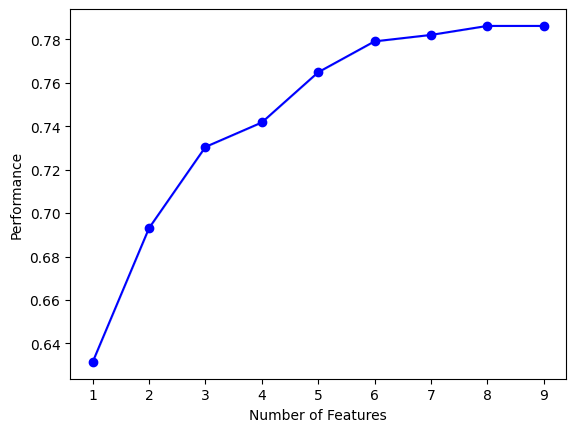

In [293]:
plot_sfs(sfs.get_metric_dict())

plt.show()

In [294]:
# 🔍 Lecture du graphique :
#
# L’axe X représente le nombre de variables (features) utilisées.
#
# L’axe Y représente la performance du modèle (souvent accuracy).
#
# On remarque que la courbe monte progressivement, puis se stabilise vers 0.78 à partir de 7–9 features.
#
# 📈 Interprétation :
#
# Cela signifie qu’en ajoutant plus de variables, ton modèle s’améliore jusqu’à environ 7 features, puis n’obtient plus de gain significatif.
#
# Donc, le sous-ensemble optimal semble être autour de 7 features.
#
# En d’autres termes, le modèle avec 7 variables est presque aussi performant que celui avec toutes les variables, mais plus simple et potentiellement plus général (moins de risque d’overfitting).
#





## Sequential Backward Selection

Sequential forward selection was able to find a feature subset that performed marginally better than the full feature set. Let's use a different sequential method and see how it compares.

Create a sequential backward selection model called `sbs`.
* Be sure to set the `estimator` parameter to `lr` and set the `forward` and `floating` parameters to the appropriate values.
* Also use the parameters `k_features=7`, `scoring='accuracy'`, and `cv=0`.

In [295]:
sbs = SFS(lr, forward = False, floating = False, k_features = 7,cv=0, scoring="accuracy")



### Fit the model

Use the `.fit()` method on `sbs` to fit the model to `X` and `y`.

In [296]:
sbs.fit(X_train,y_train)

,estimator,LogisticRegre...max_iter=1000)
,k_features,"(7, ...)"
,forward,False
,floating,False
,verbose,0
,scoring,'accuracy'
,cv,0
,n_jobs,1
,pre_dispatch,'2*n_jobs'
,clone_estimator,True
,fixed_features,None


### Inspect the results

Now that you've run the sequential backward selection algorithm on the logistic regression model with `X` and `y` you can see what features were chosen and check the model accuracy on the smaller feature set. Print `sbs.subsets_[7]` to inspect the results of sequential backward selection.

In [297]:
print(sbs.subsets_[7])

{'feature_idx': (1, 2, 3, 4, 6, 13, 17), 'cv_scores': array([0.75236967]), 'avg_score': np.float64(0.7523696682464455), 'feature_names': ('Age', 'family_history_with_overweight', 'FAVC', 'FCVC', 'CAEC', 'Automobile', 'Walking')}


### Chosen features and model accuracy

Use the dictionary `sbs.subsets_[7]` to print a tuple of chosen feature names. Then use it to print the accuracy of the model after doing sequential backward selection. How does this compare to the model's accuracy on all available features?

In [298]:
chosen_features = sbs.subsets_[7]['feature_names']
print(chosen_features)
accuracy_after_sbs = sbs.subsets_[7]['avg_score']
print(accuracy_after_sbs)
print('\n')
print("Accuracy avec toutes les features :", lr.score(X_test, y_test))


('Age', 'family_history_with_overweight', 'FAVC', 'FCVC', 'CAEC', 'Automobile', 'Walking')
0.7523696682464455


Accuracy avec toutes les features : 0.7848699763593381


### Visualize model accuracy

You can visualize the results of sequential backward floating selection just as you did with sequential forward selection. Use the code `plot_sfs(sbs.get_metric_dict())` to plot the model accuracy as a function of the number of features used.

/Users/ermanw/Projects_AI/AI_ML/ai_ml_projects/WrapperMethodsProjects/.env/lib/python3.11/site-packages/mlxtend/feature_selection/sequential_feature_selector.py:895: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  std_err = scipy.stats.sem(ary)


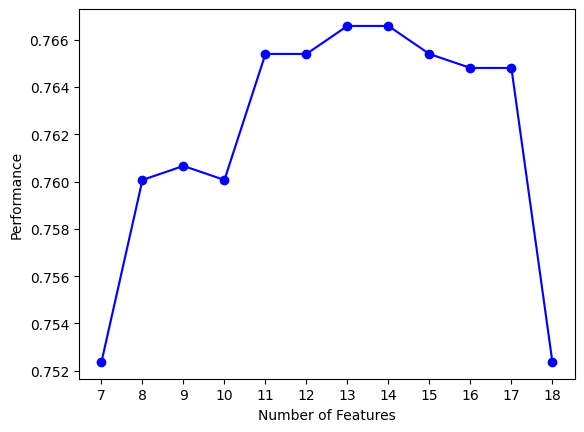

In [299]:
plot_sfs(sbs.get_metric_dict())
plt.show()

## Recursive Feature Elimination

So far you've tried two different sequential feature selection methods. Let's try one more: recursive feature elimination. First you'll standardize the data, then you'll fit the RFE model and inspect the results.

At a later step of this project, you'll need to be able to access feature names. Enter the code `features = X.columns` for use later.

In [300]:
scaler = StandardScaler()
features = X.columns


### Standardize the data

Before doing applying recursive feature elimination it is necessary to standardize the data. Standardize `X` and save it as a DataFrame by creating a `StandardScaler()` object and using the `.fit_transform()` method.

In [301]:
X_scaled = scaler.fit_transform(X_train)

### Recursive feature elimination model

Create an `RFE()` object that selects `8` features. Be sure to set the `estimator` parameter to `lr`.

In [302]:
rfe= RFE(LogisticRegression(),n_features_to_select=8,)

### Fit the model

Fit the recursive feature elimination model to `X` and `y`.

In [303]:
rfe.fit_transform(X_scaled,y_train)

array([[-0.53264595,  0.46961161,  0.35508317, ..., -0.21412338,
        -0.5325882 , -0.1729054 ],
       [-0.54423543,  0.46961161,  0.35508317, ..., -0.21412338,
        -0.5325882 , -0.1729054 ],
       [-0.23925802,  0.46961161,  0.35508317, ..., -0.21412338,
        -0.5325882 , -0.1729054 ],
       ...,
       [-0.22534243,  0.46961161,  0.35508317, ..., -0.21412338,
        -0.5325882 , -0.1729054 ],
       [-0.22377429,  0.46961161,  0.35508317, ..., -0.21412338,
        -0.5325882 , -0.1729054 ],
       [-0.68708178,  0.46961161,  0.35508317, ..., -0.21412338,
        -0.5325882 , -0.1729054 ]], shape=(1688, 8))

### Inspect chosen features

Now that you've fit the RFE model you can evaluate the results. Create a list of chosen feature names and call it `rfe_features`. You can use a list comprehension and filter the features in `zip(features, rfe.support_)` based on whether their support is `True` (meaning the model kept them) or `False` (meaning the model eliminated them).

In [304]:
rfe_features = [f for(f,support) in zip(features, rfe.support_)if support ]
print(rfe_features)

['Age', 'family_history_with_overweight', 'FAVC', 'FCVC', 'CAEC', 'SCC', 'Automobile', 'Walking']


### Model accuracy

Use the `.score()` method on `rfe` and print the model accuracy after doing recursive feature elimination. How does this compare to the model's accuracy on all available features?

In [305]:
accuracy = rfe.score(X_scaled, y_train)
print(accuracy)
print('\n')
print("Accuracy avec toutes les features :", lr.score(X_test, y_test))



0.7612559241706162


Accuracy avec toutes les features : 0.7848699763593381
